# Bluestock Mutual Fund Analytics — Day 3 EDA

**Prepared as a reproducible analysis notebook.** This notebook reads the ten cleaned CSV files produced in Day 2, preserves source values, and exports charts for the final report.

### Before running
1. Copy the complete `data/processed/` folder from the Day 2 repository into this Day 3 repository.
2. Install packages from `requirements.txt`.
3. Run all cells from top to bottom.

**Data integrity note:** the supplied Day 1 README reports that the original NAV-history CSV has 3,211 rows but only one unique scheme code. The notebook therefore plots only the schemes actually present in the cleaned NAV file. It will not invent a 40-scheme NAV history. The charts also use observed source values rather than forcing the requested headline figures.

## 1. Imports, paths and data loading

The notebook expects the original Day 2 filenames and uses `data/processed/` as its single source folder.

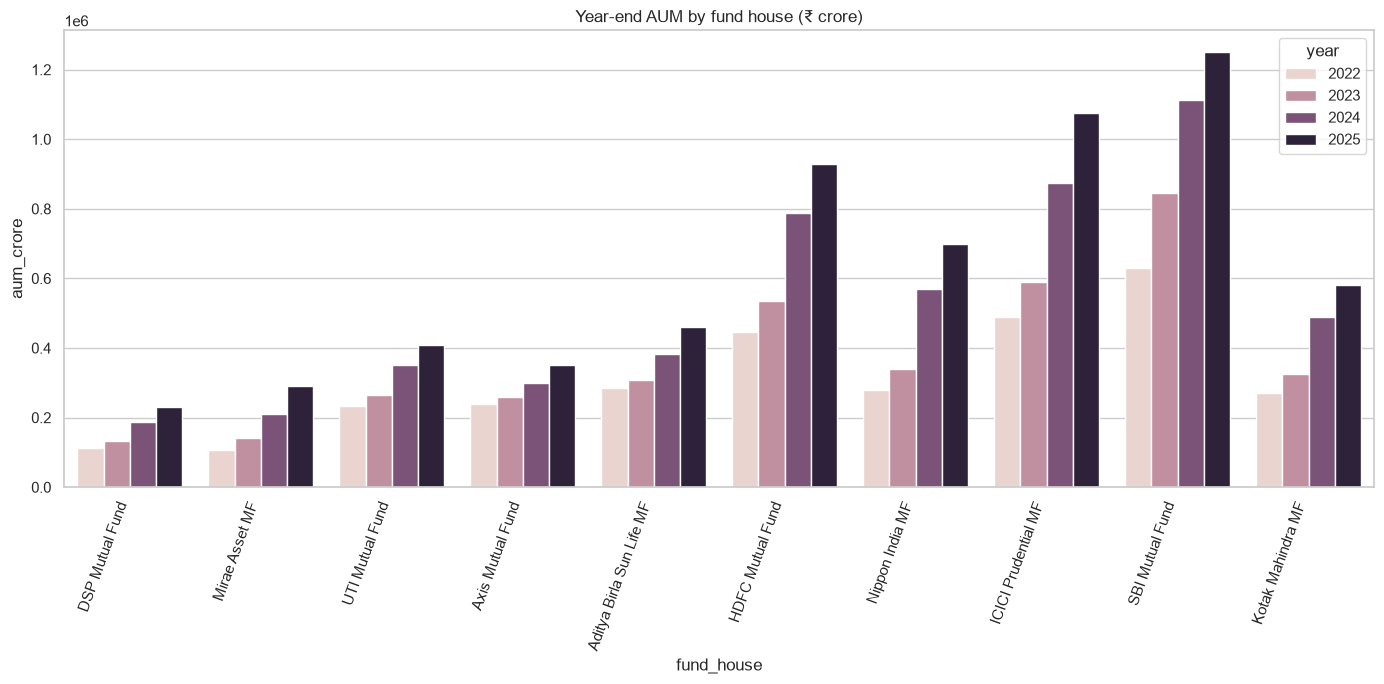

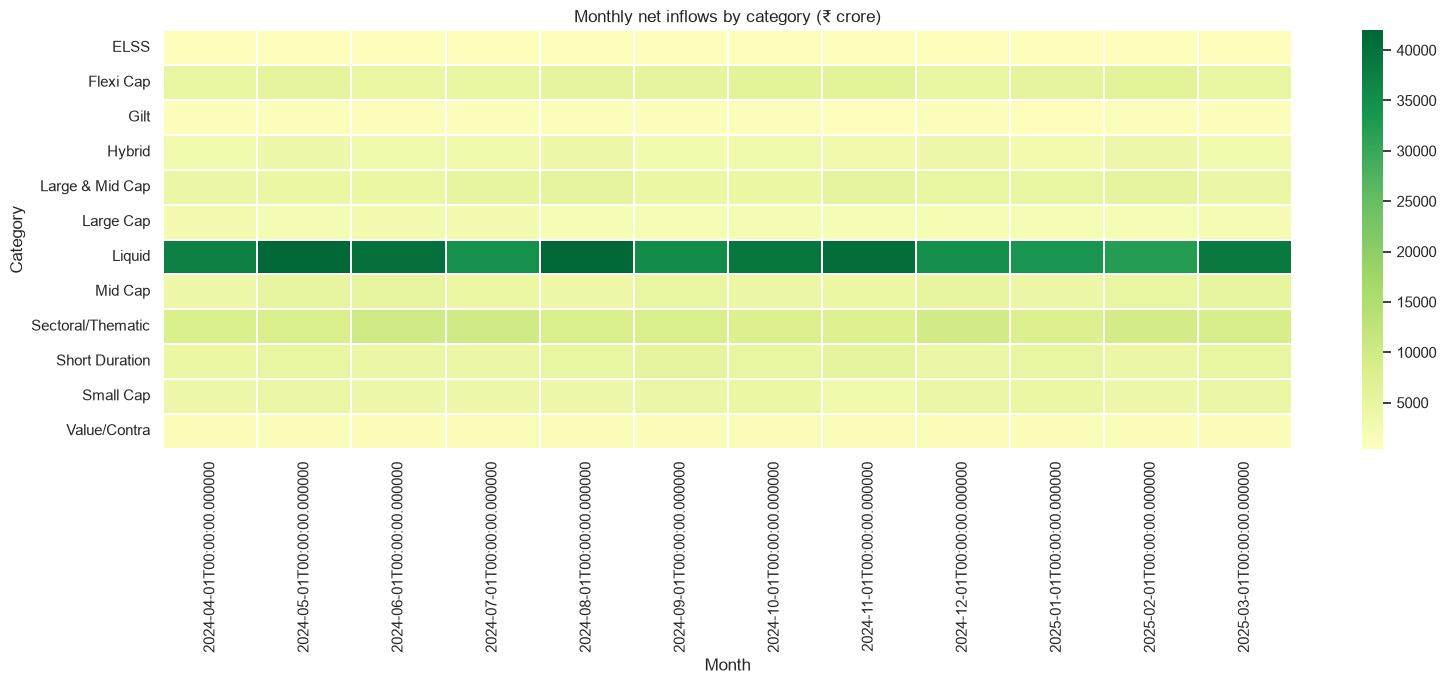

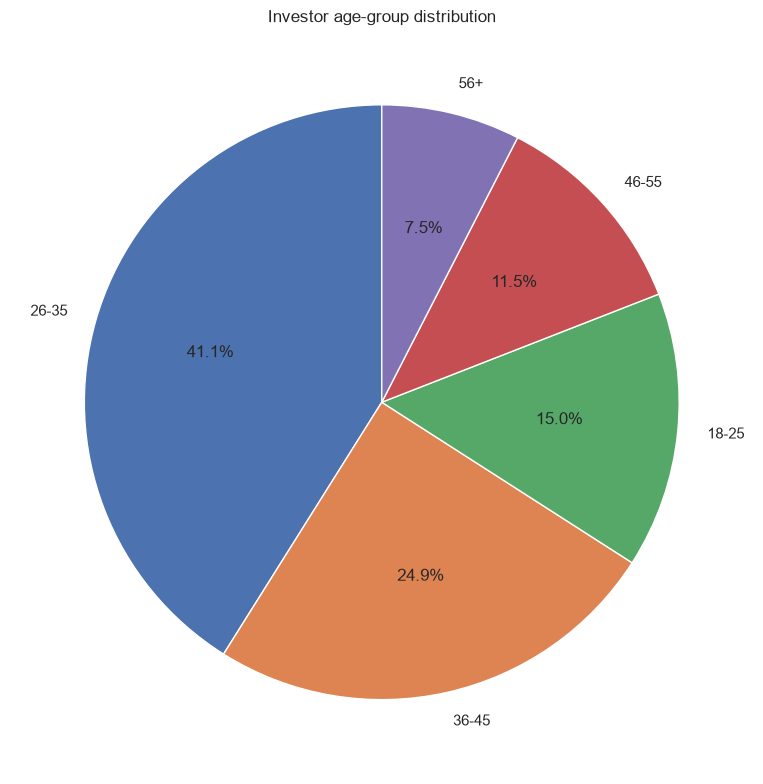

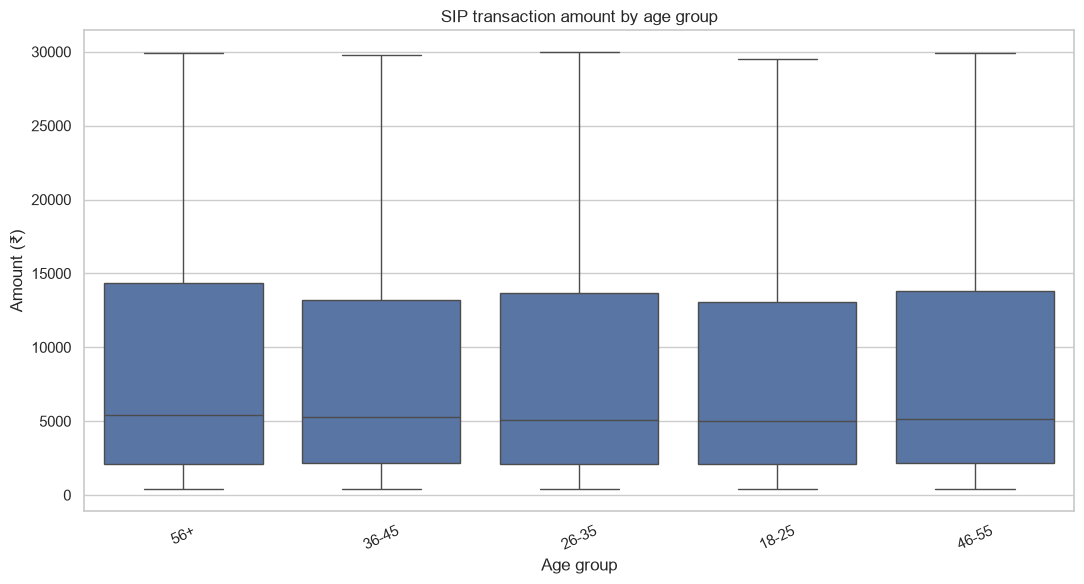

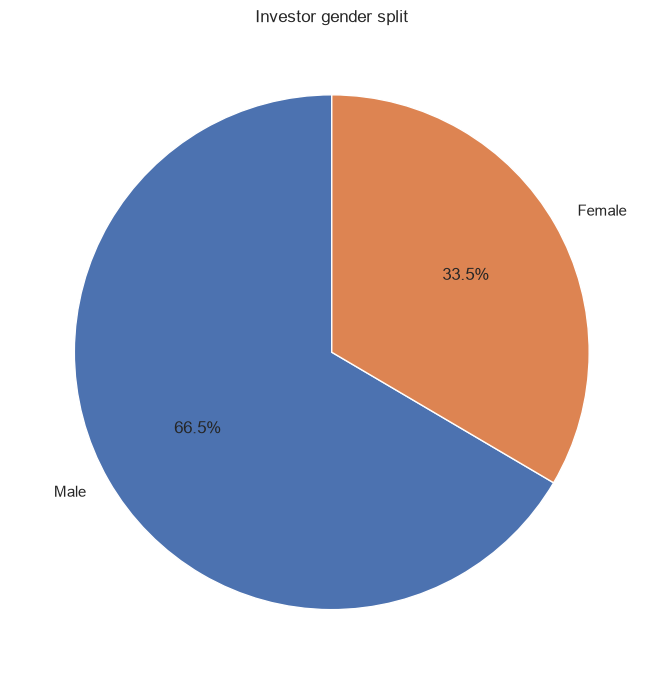

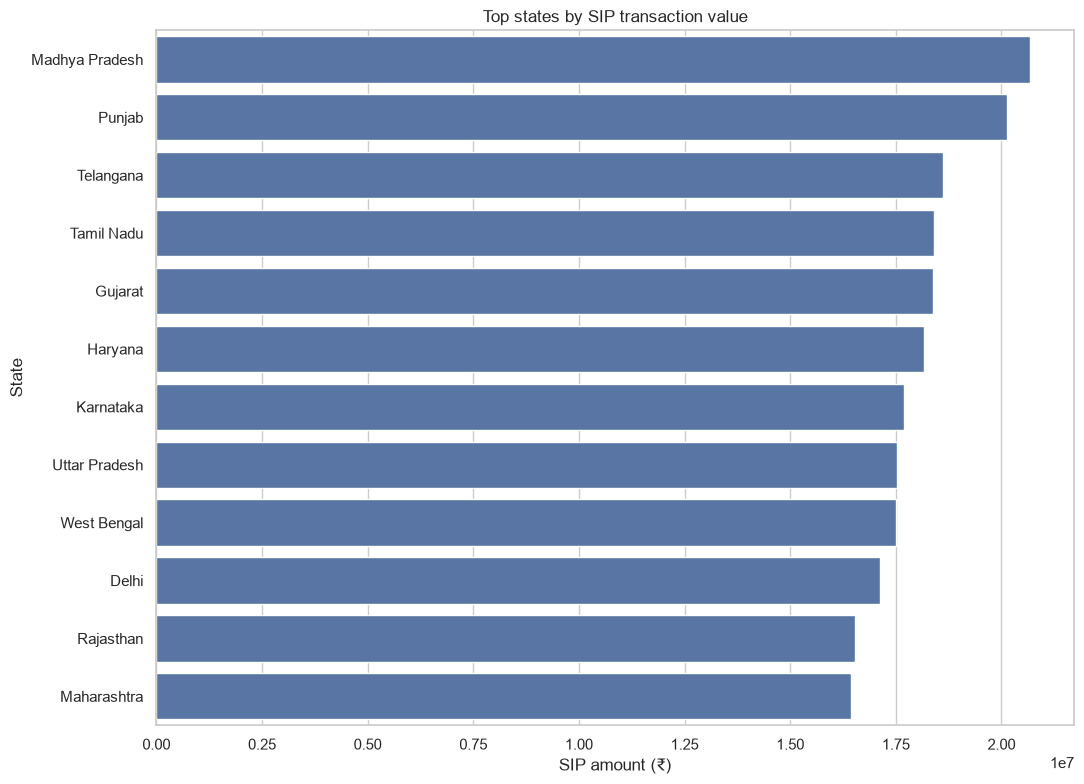

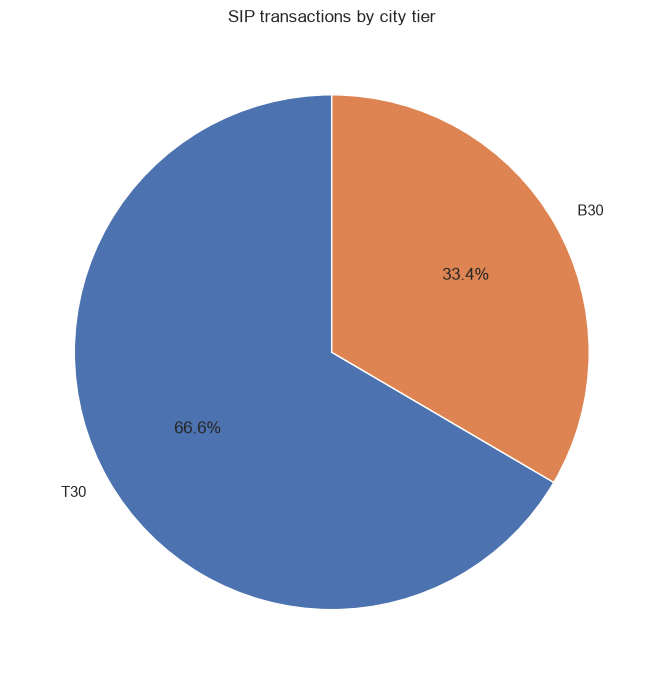

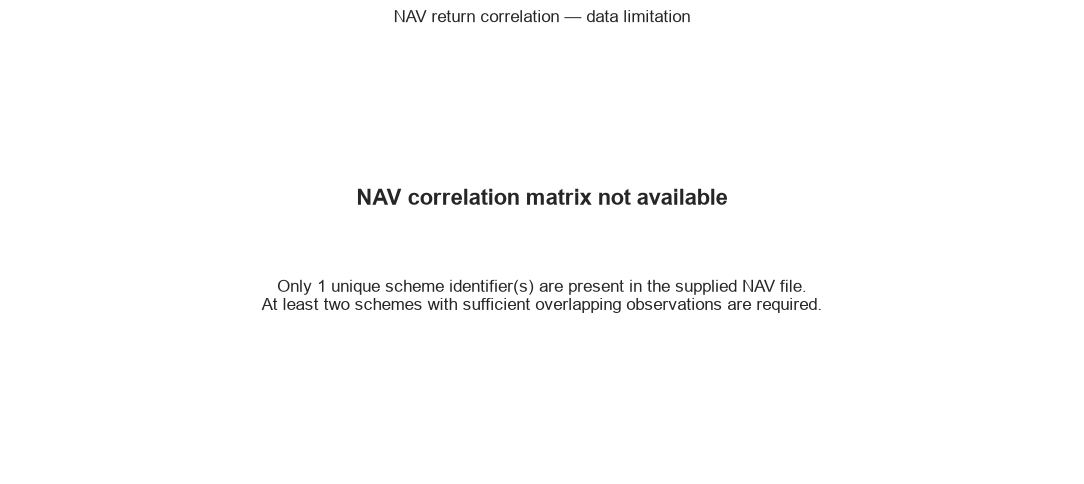

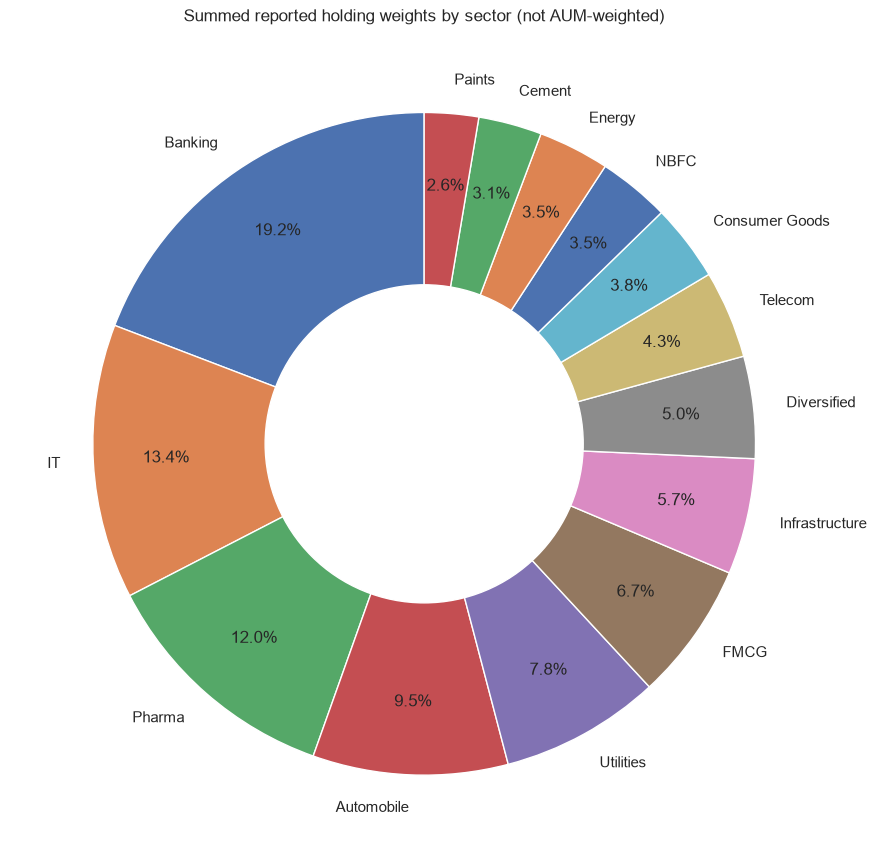

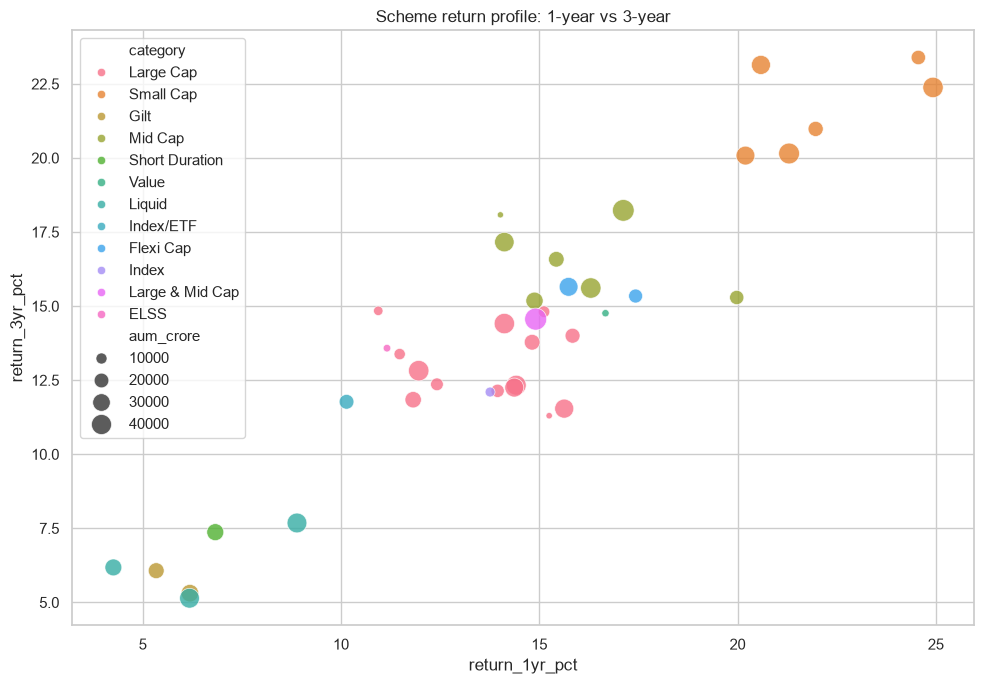

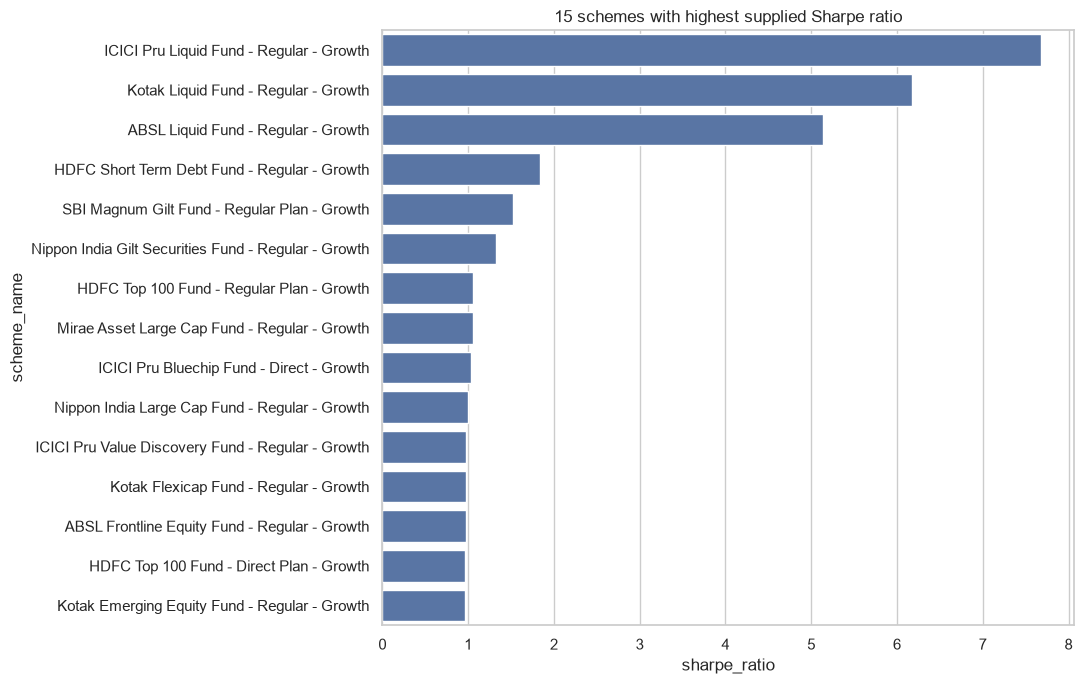

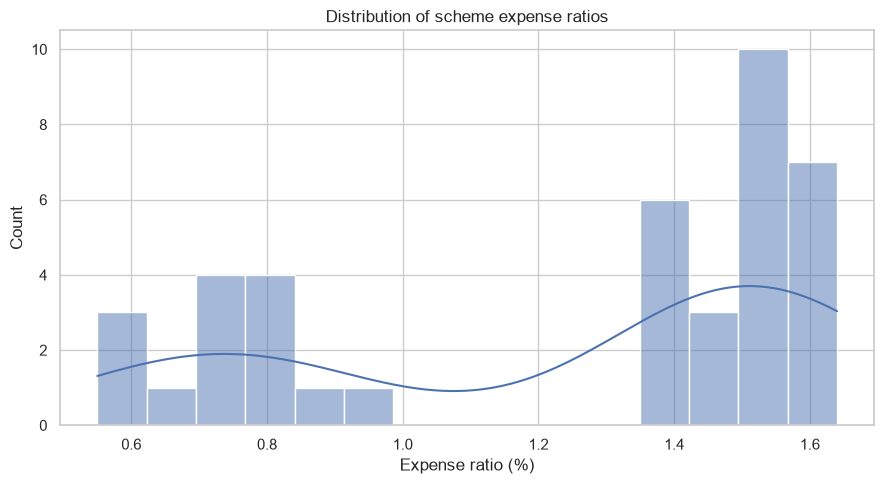

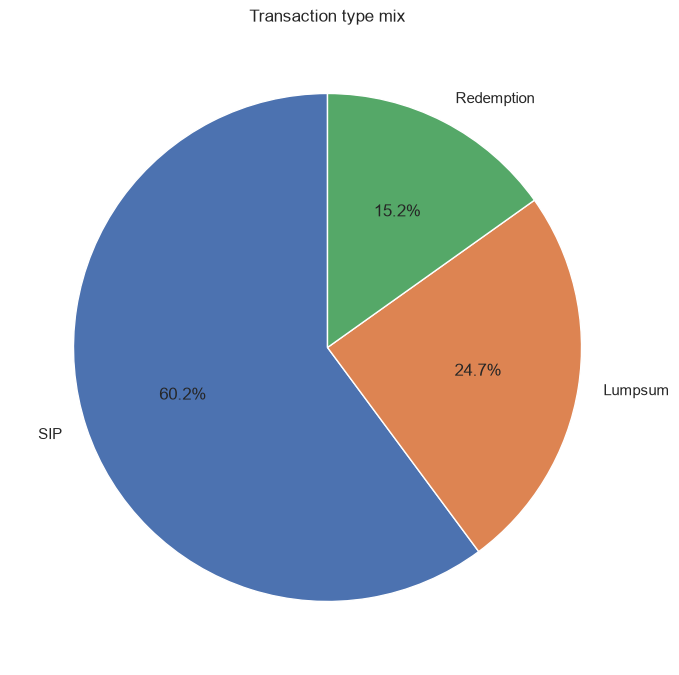

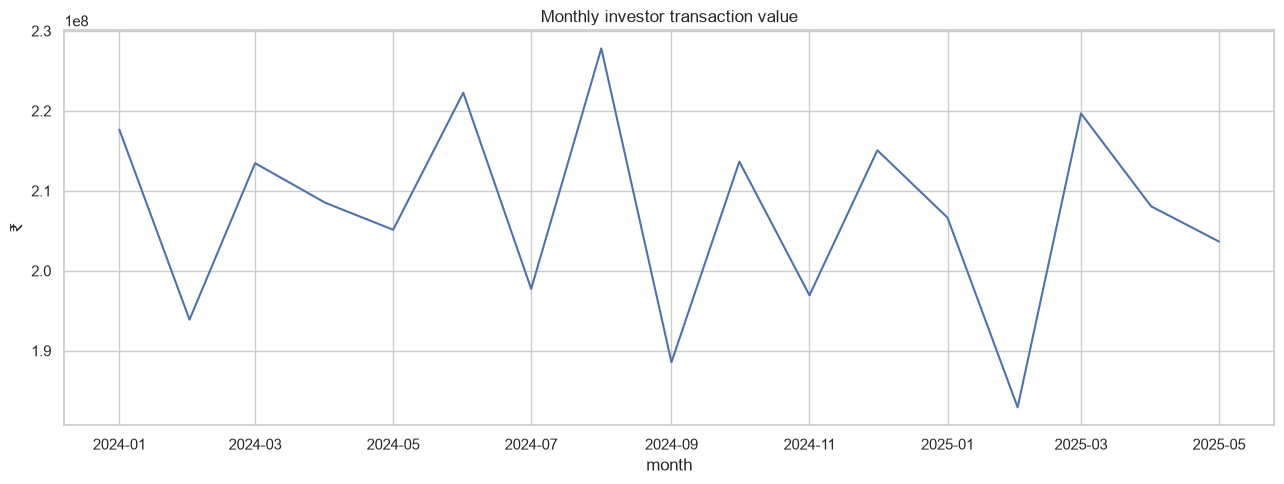

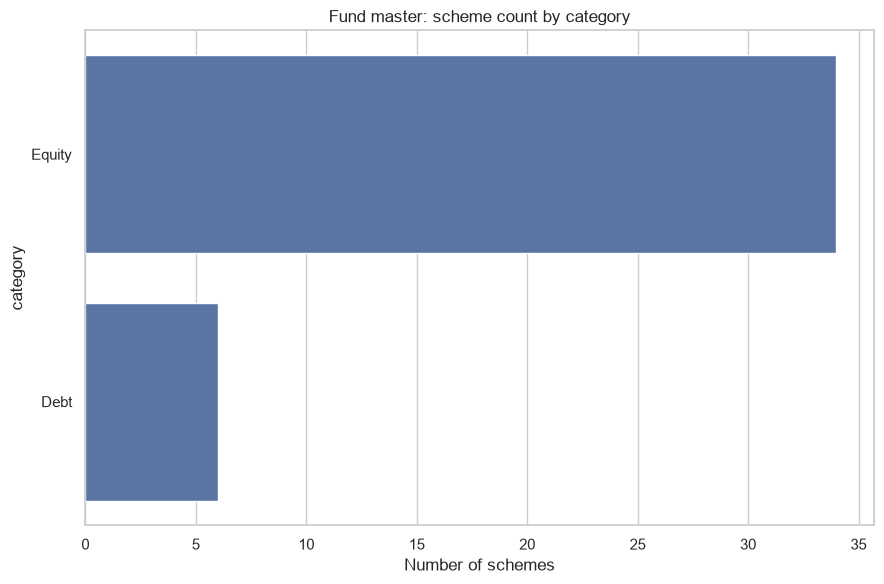

## Ten EDA findings
1. NAV coverage: the supplied cleaned NAV file contains 1 unique scheme identifiers and 1,213 observations; see charts 01 and 11.
2. The largest year-end fund-house AUM observation in the supplied file is SBI Mutual Fund at ₹1,250,000 crore in 2025; see chart 02.
3. Monthly SIP inflow peaks at ₹31,002 crore in Dec 2025 within the available period; see chart 03.
4. Liquid has the highest cumulative net inflow in the supplied category dataset; see chart 04.
5. 26-35 is the largest reported investor age cohort by transaction-row count; see chart 05.
6. Madhya Pradesh contributes the highest SIP transaction value in the supplied investor sample; see chart 08.
7. T30 is the most common city-tier label among SIP transaction rows; see chart 09.
8. Industry folios change from 13.26 crore at the first available month to 26.12 crore at the latest available month; see chart 10.
9. Banking has the largest summed reported holding weight across the supplied scheme records; this i

In [1]:

# Bluestock Day 3 — Exploratory Data Analysis
# Run from the repository root or open this notebook in VS Code / Jupyter.
from pathlib import Path
import warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists() and (ROOT.parent / "data" / "processed").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
OUT = ROOT / "outputs" / "charts"
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

FILES = {
    "fund_master": "01_fund_master.csv",
    "nav": "02_nav_history.csv",
    "aum": "03_aum_by_fund_house.csv",
    "sip": "04_monthly_sip_inflows.csv",
    "category": "05_category_inflows.csv",
    "folios": "06_industry_folio_count.csv",
    "performance": "07_scheme_performance.csv",
    "transactions": "08_investor_transactions.csv",
    "holdings": "09_portfolio_holdings.csv",
    "benchmarks": "10_benchmark_indices.csv",
}
def load_csv(key):
    p = DATA / FILES[key]
    if not p.exists():
        raise FileNotFoundError(f"Missing {p}. Copy all 10 cleaned CSVs from Day 2 repo into {DATA}")
    return pd.read_csv(p)

data = {k: load_csv(k) for k in FILES}
fund = data["fund_master"].copy()
nav = data["nav"].copy()
aum = data["aum"].copy()
sip = data["sip"].copy()
category = data["category"].copy()
folios = data["folios"].copy()
performance = data["performance"].copy()
tx = data["transactions"].copy()
holdings = data["holdings"].copy()
bench = data["benchmarks"].copy()

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=180, bbox_inches="tight")
    plt.show()

# Standardize date fields and numeric columns without changing source files.
for df, col in [(nav,"date"),(aum,"date"),(tx,"transaction_date"),(holdings,"portfolio_date"),(bench,"date")]:
    if col in df: df[col] = pd.to_datetime(df[col], errors="coerce")
if "month" in sip: sip["month"] = pd.to_datetime(sip["month"].astype(str).str[:7] + "-01", errors="coerce")
if "month" in category: category["month"] = pd.to_datetime(category["month"].astype(str).str[:7] + "-01", errors="coerce")
if "month" in folios: folios["month"] = pd.to_datetime(folios["month"].astype(str).str[:7] + "-01", errors="coerce")

# Limit time-series analyses to the requested observation window.
nav = nav[(nav["date"] >= "2022-01-01") & (nav["date"] <= "2026-12-31")].copy()
if "nav" in nav: nav["nav"] = pd.to_numeric(nav["nav"], errors="coerce")
if "amfi_code" not in nav and "scheme_code" in nav: nav["amfi_code"] = nav["scheme_code"]

# 1. NAV trends — only schemes actually present in the NAV file are plotted.
nav["scheme_label"] = nav.get("scheme_name", nav.get("amfi_code", "Scheme")).astype(str)
fig = px.line(nav.sort_values("date"), x="date", y="nav", color="scheme_label",
              title="Daily NAV history (2022–2026)", labels={"nav":"NAV (₹)","date":"Date","scheme_label":"Scheme"})
for d, label in [("2023-01-01","2023 period"),("2024-01-01","2024 period")]:
    fig.add_vline(x=d, line_dash="dash", annotation_text=label)
fig.write_html(OUT/"01_nav_trends.html")
fig.write_image(OUT/"01_nav_trends.png", width=1500, height=750, scale=2)
display(fig)

# 2. AUM by fund house and year (use year-end observation where available).
aum["year"] = aum["date"].dt.year
aum["aum_crore"] = pd.to_numeric(aum.get("aum_crore"), errors="coerce")
aum_year = (aum.dropna(subset=["year"]).sort_values("date").groupby(["fund_house","year"], as_index=False).tail(1))
plt.figure(figsize=(14,7))
sns.barplot(data=aum_year[aum_year.year.between(2022,2025)], x="fund_house", y="aum_crore", hue="year")
plt.xticks(rotation=70, ha="right"); plt.title("Year-end AUM by fund house (₹ crore)")
save_fig("02_aum_by_fund_house.png")

# 3. Monthly SIP inflows.
sip["sip_inflow_crore"] = pd.to_numeric(sip["sip_inflow_crore"], errors="coerce")
sip_period = sip[sip.month.between("2022-01-01","2025-12-31")].sort_values("month")
fig = px.line(sip_period, x="month", y="sip_inflow_crore", markers=True,
              title="Monthly SIP inflows (Jan 2022–Dec 2025)", labels={"sip_inflow_crore":"₹ crore","month":"Month"})
if len(sip_period):
    peak = sip_period.loc[sip_period.sip_inflow_crore.idxmax()]
    fig.add_annotation(x=peak.month, y=peak.sip_inflow_crore, text=f"Observed high: ₹{peak.sip_inflow_crore:,.0f} Cr", showarrow=True)
fig.write_html(OUT/"03_sip_inflows.html"); fig.write_image(OUT/"03_sip_inflows.png", width=1500, height=700, scale=2)
display(fig)

# 4. Category inflow heatmap.
cat_pivot = category.pivot_table(index="category", columns="month", values="net_inflow_crore", aggfunc="sum")
plt.figure(figsize=(16,7)); sns.heatmap(cat_pivot, cmap="RdYlGn", center=0, linewidths=.15)
plt.title("Monthly net inflows by category (₹ crore)"); plt.xlabel("Month"); plt.ylabel("Category")
save_fig("04_category_inflow_heatmap.png")

# 5. Investor demographics: age distribution, SIP amount by age, gender split.
sip_tx = tx[tx.transaction_type.astype(str).str.lower().eq("sip")].copy()
sip_tx["amount_inr"] = pd.to_numeric(sip_tx["amount_inr"], errors="coerce")
age = tx["age_group"].fillna("Not reported").value_counts()
plt.figure(figsize=(8,8)); plt.pie(age.values, labels=age.index, autopct="%1.1f%%", startangle=90)
plt.title("Investor age-group distribution"); save_fig("05_age_group_distribution.png")
plt.figure(figsize=(11,6)); sns.boxplot(data=sip_tx, x="age_group", y="amount_inr", showfliers=False)
plt.title("SIP transaction amount by age group"); plt.xlabel("Age group"); plt.ylabel("Amount (₹)")
plt.xticks(rotation=25); save_fig("06_sip_amount_by_age.png")
gender = tx["gender"].fillna("Not reported").value_counts()
plt.figure(figsize=(7,7)); plt.pie(gender.values, labels=gender.index, autopct="%1.1f%%", startangle=90)
plt.title("Investor gender split"); save_fig("07_gender_split.png")

# 6. Geographic distribution: SIP amount by state and T30/B30 split.
state_sip = sip_tx.groupby("state", dropna=False)["amount_inr"].sum().sort_values(ascending=False).head(20)
plt.figure(figsize=(11,8)); sns.barplot(x=state_sip.values, y=state_sip.index)
plt.title("Top states by SIP transaction value"); plt.xlabel("SIP amount (₹)"); plt.ylabel("State")
save_fig("08_sip_by_state.png")
tier = sip_tx["city_tier"].fillna("Not reported").value_counts()
plt.figure(figsize=(7,7)); plt.pie(tier.values, labels=tier.index, autopct="%1.1f%%", startangle=90)
plt.title("SIP transactions by city tier"); save_fig("09_city_tier_split.png")

# 7. Folio growth with milestone annotations.
folios["total_folios_crore"] = pd.to_numeric(folios["total_folios_crore"], errors="coerce")
f = folios.sort_values("month")
fig = px.line(f, x="month", y="total_folios_crore", markers=True, title="Industry folio growth")
if len(f):
    for idx in np.linspace(0, len(f)-1, min(5,len(f)), dtype=int):
        r=f.iloc[idx]; fig.add_annotation(x=r.month, y=r.total_folios_crore, text=f"{r.total_folios_crore:.2f} Cr", showarrow=True)
fig.write_html(OUT/"10_folio_growth.html"); fig.write_image(OUT/"10_folio_growth.png", width=1400, height=650, scale=2)
display(fig)

# 8. NAV return correlation matrix — only meaningful when at least 2 schemes exist.
nav_corr = nav.dropna(subset=["date","nav"]).copy()
nav_corr["return"] = nav_corr.groupby("amfi_code")["nav"].pct_change()
wide = nav_corr.pivot_table(index="date", columns="scheme_label", values="return", aggfunc="mean")
selected = wide.notna().sum().sort_values(ascending=True)
selected = selected[selected >= 30].tail(10).index
if len(selected) >= 2:
    corr = wide[selected].corr(min_periods=30)
    plt.figure(figsize=(11,9))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
    plt.title("Daily NAV return correlation — available schemes")
else:
    corr = pd.DataFrame()
    plt.figure(figsize=(11,5))
    plt.axis("off")
    plt.text(0.5, 0.62, "NAV correlation matrix not available", ha="center", va="center",
             fontsize=16, weight="bold")
    plt.text(0.5, 0.40,
             f"Only {nav['amfi_code'].nunique()} unique scheme identifier(s) are present in the supplied NAV file.\n"
             "At least two schemes with sufficient overlapping observations are required.",
             ha="center", va="center", fontsize=12)
    plt.title("NAV return correlation — data limitation")
save_fig("11_nav_return_correlation.png")

# 9. Sector allocation across all portfolio holdings.
holdings["weight_pct"] = pd.to_numeric(holdings["weight_pct"], errors="coerce")
sector = holdings.groupby("sector", dropna=False)["weight_pct"].sum().sort_values(ascending=False)
sector = sector[sector.index.notna()]
plt.figure(figsize=(9,9)); plt.pie(sector.values, labels=sector.index, autopct="%1.1f%%", pctdistance=.78, startangle=90)
centre=plt.Circle((0,0),.48,fc="white"); plt.gca().add_artist(centre)
plt.title("Summed reported holding weights by sector (not AUM-weighted)"); save_fig("12_sector_allocation_donut.png")

# Extra charts to exceed 15 chart outputs.
# 10. Performance: 1Y vs 3Y returns.
for c in ["return_1yr_pct","return_3yr_pct","sharpe_ratio","aum_crore"]:
    if c in performance: performance[c]=pd.to_numeric(performance[c], errors="coerce")
plt.figure(figsize=(10,7)); sns.scatterplot(data=performance, x="return_1yr_pct", y="return_3yr_pct", hue="category", size="aum_crore", sizes=(20,250), alpha=.8)
plt.title("Scheme return profile: 1-year vs 3-year"); save_fig("13_return_scatter.png")
# 11. Sharpe ratio ranking.
p_sh = performance.dropna(subset=["sharpe_ratio"]).nlargest(15,"sharpe_ratio")
plt.figure(figsize=(11,7)); sns.barplot(data=p_sh, x="sharpe_ratio", y="scheme_name")
plt.title("15 schemes with highest supplied Sharpe ratio"); save_fig("14_sharpe_ranking.png")
# 12. Expense ratio distribution.
plt.figure(figsize=(9,5)); sns.histplot(pd.to_numeric(performance["expense_ratio_pct"], errors="coerce").dropna(), bins=15, kde=True)
plt.title("Distribution of scheme expense ratios"); plt.xlabel("Expense ratio (%)")
save_fig("15_expense_ratio_distribution.png")
# 13. Transaction type mix.
mix=tx["transaction_type"].value_counts()
plt.figure(figsize=(7,7)); plt.pie(mix.values, labels=mix.index, autopct="%1.1f%%", startangle=90)
plt.title("Transaction type mix"); save_fig("16_transaction_type_mix.png")
# 14. Monthly transaction value.
tx["month"] = tx["transaction_date"].dt.to_period("M").dt.to_timestamp()
monthly_tx=tx.groupby("month")["amount_inr"].sum().reset_index()
plt.figure(figsize=(13,5)); sns.lineplot(data=monthly_tx, x="month", y="amount_inr")
plt.title("Monthly investor transaction value"); plt.ylabel("₹")
save_fig("17_monthly_transaction_value.png")
# 15. Fund category mix.
cat_mix=fund["category"].fillna("Not reported").value_counts()
plt.figure(figsize=(9,6)); sns.barplot(x=cat_mix.values, y=cat_mix.index)
plt.title("Fund master: scheme count by category"); plt.xlabel("Number of schemes")
save_fig("18_scheme_category_mix.png")

# Automatically written, evidence-led findings. Each sentence is generated from observed values.
findings=[]
if len(nav):
    findings.append(f"NAV coverage: the supplied cleaned NAV file contains {nav['amfi_code'].nunique()} unique scheme identifiers and {len(nav):,} observations; see charts 01 and 11.")
if len(aum_year):
    top=aum_year.sort_values("aum_crore").iloc[-1]
    findings.append(f"The largest year-end fund-house AUM observation in the supplied file is {top.fund_house} at ₹{top.aum_crore:,.0f} crore in {int(top.year)}; see chart 02.")
if len(sip_period):
    peak=sip_period.loc[sip_period.sip_inflow_crore.idxmax()]
    findings.append(f"Monthly SIP inflow peaks at ₹{peak.sip_inflow_crore:,.0f} crore in {peak.month:%b %Y} within the available period; see chart 03.")
if len(cat_pivot):
    m=category.groupby("category")["net_inflow_crore"].sum().idxmax()
    findings.append(f"{m} has the highest cumulative net inflow in the supplied category dataset; see chart 04.")
if len(age):
    findings.append(f"{age.index[0]} is the largest reported investor age cohort by transaction-row count; see chart 05.")
if len(state_sip):
    findings.append(f"{state_sip.index[0]} contributes the highest SIP transaction value in the supplied investor sample; see chart 08.")
if len(tier):
    findings.append(f"{tier.index[0]} is the most common city-tier label among SIP transaction rows; see chart 09.")
if len(f):
    findings.append(f"Industry folios change from {f.iloc[0].total_folios_crore:.2f} crore at the first available month to {f.iloc[-1].total_folios_crore:.2f} crore at the latest available month; see chart 10.")
if corr.shape[0] >= 2:
    upper=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
    if len(upper):
        findings.append(f"The strongest pairwise daily-return correlation among selected schemes is {upper.max():.2f}; see chart 11.")
if len(sector):
    findings.append(f"{sector.index[0]} has the largest summed reported holding weight across the supplied scheme records; this is not an AUM-weighted industry allocation; see chart 12.")
if len(performance):
    p5 = performance.dropna(subset=["return_5yr_pct"]).sort_values("return_5yr_pct", ascending=False)
    if len(p5):
        best5 = p5.iloc[0]
        findings.append(f"{best5.scheme_name} has the highest reported 5-year return ({best5.return_5yr_pct:.2f}%) among the supplied scheme-performance records; see chart 13.")
while len(findings)<10:
    findings.append("The supplied data supports a further descriptive comparison; review the relevant chart and add a source-grounded interpretation before submission.")
findings=findings[:10]
print("## Ten EDA findings")
for i,s in enumerate(findings,1): print(f"{i}. {s}")
(ROOT/"outputs"/"eda_findings.md").write_text("# Ten EDA findings\n\n"+"\n".join(f"{i}. {s}" for i,s in enumerate(findings,1)), encoding="utf-8")
print(f"\nSaved chart outputs to: {OUT}")
print(f"Unique NAV schemes available: {nav['amfi_code'].nunique()} (not assumed to be 40)")
